# 07-1 문제 해결: 학습 진행 횟수 세기 (Checkpointer)

`07-1_short_term_memory.ipynb`에서 살펴본 Checkpointer의 `thread_id`별 State 유지를 응용해본다.  
이번에는 LLM과 메시지 목록 대신, **숫자를 스레드별로 누적**하는 Graph를 직접 만든다.  
LLM 호출이 없어서 API 키 없이도 실습할 수 있다.  

**시나리오:** 학습 진행을 추적하는 챗봇이다.  
학습자가 문제를 하나 풀 때마다 `"solve"`라고 보내면 지금까지 푼 문제 수를 알려주고,  
`"check"`라고 보내면 숫자를 바꾸지 않고 현재 수만 알려준다.  
같은 대화(`thread_id`)에서는 숫자가 누적되고, 새 대화를 열면 0부터 다시 시작해야 한다.

## 요구사항
- State에는 `action`(`"solve"` 또는 `"check"`), `solved_count`, `result` 세 필드가 있다.
- `solved_count`는 `Annotated[int, operator.add]`로 선언해, `invoke()`에 넘긴 값이 기존 채널 값에 **더해진 뒤** Node로 전달되게 한다.
- `"solve"`를 보내면 Node는 누적된 `solved_count`를 사용해 `"{n}문제 해결"` 형태의 문자열을 `result`에 담아 반환한다.
- `"check"`를 보내면 숫자는 바꾸지 않고(`solved_count=0`을 넘긴다) `"지금까지 {n}문제 해결"` 형태로 반환한다.
- 같은 `thread_id`로 `"solve"`를 여러 번 호출하면 숫자가 누적되어야 한다.
- 새로운 `thread_id`로 `"check"`를 호출하면 이전 스레드와 무관하게 **0부터** 시작해야 한다.
- `Store`는 쓰지 않는다. 이번 문제는 단기 메모리(Checkpointer)만 다룬다.

## 힌트
- `Annotated[int, operator.add]`로 선언한 필드는, `invoke()`에서 넘긴 값이 **그 채널의 기존 값에 더해진 뒤** Node 함수의 `state`에 반영된다. 즉 Node 안에서 `state.solved_count`를 읽으면 이미 합산된 값이다.
- `"check"`에서 값을 그대로 유지하려면 `solved_count=0`을 넘긴다(0을 더해도 값은 바뀌지 않는다).
- 처음 쓰는 `thread_id`는 이전 Checkpoint가 없으므로, Pydantic 필드에 기본값(`= 0`)을 지정해 두면 첫 호출도 자연스럽게 처리된다.
- 07-1에서 `messages: Annotated[list, add_messages]`로 메시지를 쌓은 것과 같은 원리다. 리스트 대신 정수에 `operator.add`를 적용한다고 생각하면 된다.

In [2]:
import operator
from typing import Annotated
from pydantic import BaseModel
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import START, END, StateGraph

class ProgressState(BaseModel):
    action: str        # "solve" 또는 "check"
    # TODO: solved_count 필드를 추가한다. Annotated[int, operator.add]로 선언하고 기본값은 0으로 둔다.
    solved_count: Annotated[int, operator.add] = 0
    result: str = ""

def progress_node(state: ProgressState) -> dict:
    if state.action == "solve":
        # TODO: 누적된 state.solved_count를 사용해 "{n}문제 해결" 형태의 문자열을 반환한다.
        return {"result": f"{state.solved_count}문제 해결"}
    if state.action == "check":
        # TODO: state.solved_count를 사용해 "지금까지 {n}문제 해결" 형태의 문자열을 반환한다.
        return {"result": f"지금까지 {state.solved_count}문제 해결"}
    raise ValueError("action은 solve 또는 check여야 한다")

progress_builder = StateGraph(ProgressState)
progress_builder.add_node("progress", progress_node)
progress_builder.add_edge(START, "progress")
progress_builder.add_edge("progress", END)

progress_checkpointer = InMemorySaver()
progress_graph = progress_builder.compile(checkpointer=progress_checkpointer)

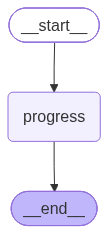

In [4]:
progress_graph

## 자가 점검용 테스트
아래 테스트를 모두 통과하면 완성이다. 통과하지 못하면 `solved_count` 필드의 reducer 선언과, Node가 `state.solved_count`를 그대로 읽어서 쓰는지(직접 더하지 않는지)를 확인한다.

In [3]:
alice = {"configurable": {"thread_id": "learner-alice"}}
bob = {"configurable": {"thread_id": "learner-bob"}}

r1 = progress_graph.invoke({"action": "solve", "solved_count": 1, "result": ""}, config=alice)
assert r1["result"] == "1문제 해결"

r2 = progress_graph.invoke({"action": "solve", "solved_count": 1, "result": ""}, config=alice)
assert r2["result"] == "2문제 해결"

r3 = progress_graph.invoke({"action": "solve", "solved_count": 1, "result": ""}, config=alice)
assert r3["result"] == "3문제 해결"

check_alice = progress_graph.invoke({"action": "check", "solved_count": 0, "result": ""}, config=alice)
assert check_alice["result"] == "지금까지 3문제 해결"

check_bob = progress_graph.invoke({"action": "check", "solved_count": 0, "result": ""}, config=bob)
assert check_bob["result"] == "지금까지 0문제 해결"  # 새 thread_id라 0부터 시작

bob_solve = progress_graph.invoke({"action": "solve", "solved_count": 1, "result": ""}, config=bob)
assert bob_solve["result"] == "1문제 해결"

check_alice_again = progress_graph.invoke({"action": "check", "solved_count": 0, "result": ""}, config=alice)
assert check_alice_again["result"] == "지금까지 3문제 해결"  # bob의 solve와 무관하게 유지

print("모든 테스트 통과")

모든 테스트 통과
